
# Image-Level Failure Concentration Analysis

## 1. Research Objective

Previous analyses identified cases where explanation similarity remained high despite substantial deterioration in attribution alignment with radiologist-annotated opacity regions.

However, these analyses primarily examined individual image–method–corruption evaluations. Because each image was evaluated repeatedly across explanation methods, corruption types, and severity levels, the distribution of failures across unique images remains unclear.

This notebook investigates whether stability–localization disagreements are concentrated in a small subset of images or distributed broadly across the evaluated chest X-rays.

### Research Questions

1. How many unique images exhibit at least one stability–localization disagreement?
2. Are disagreement evaluations concentrated in a relatively small number of images?
3. Do the same images exhibit disagreements across multiple explanation methods?
4. Do disagreements recur across different corruption types and severity levels?

### Operational Definition

An evaluation is classified as a stability–localization disagreement when:

- Explanation similarity is at least 0.80.
- Localization alignment decreases by at least 0.05 relative to the original image.

The analysis includes 150 annotated positive chest X-ray images, each evaluated using three explanation methods and six corruption conditions.

### Analysis Approach

We aggregate disagreement indicators at the image level and examine:

- Number and proportion of images with at least one disagreement.
- Distribution of disagreement counts per image.
- Concentration of disagreements among the most frequently affected images.
- Recurrence across explanation methods and corruption conditions.

This analysis is descriptive and exploratory. Repeated evaluations of the same image are treated as related observations, and image-level recurrence is not interpreted as evidence of patient-level risk or clinical unreliability.


In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

data_path = Path(
    "/content/drive/MyDrive/XAI_project_Expo_1_folder/"
    "Results/ExpandedEvaluation/"
    "stability_localization_area_enriched.csv"
)

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
print("Unique images:", df["sop_uid"].nunique())
print("Methods:", df["method"].unique())

# Reconstruct disagreement from the original thresholds
df["disagreement_audit"] = (df["explanation_similarity"] >= 0.80) & (
    df["alignment_change"] <= -0.05
)

print("Disagreement evaluations:", int(df["disagreement_audit"].sum()))

assert len(df) == 2700
assert df["sop_uid"].nunique() == 150
assert df["disagreement_audit"].sum() == 171

print("Dataset loaded and validated successfully.")

Mounted at /content/drive
Dataset shape: (2700, 24)
Unique images: 150
Methods: ['Integrated Gradients' 'Occlusion Sensitivity' 'Score-CAM']
Disagreement evaluations: 171
Dataset loaded and validated successfully.


In [ ]:
# Image-level disagreement frequency

image_failure_counts = (
    df.groupby("sop_uid")
    .agg(
        n_evaluations=("disagreement_audit", "size"),
        n_disagreements=("disagreement_audit", "sum"),
    )
    .reset_index()
)

# Percentage of evaluations with disagreements per image
image_failure_counts["disagreement_rate"] = (
    image_failure_counts["n_disagreements"] / image_failure_counts["n_evaluations"]
)

# Image-level summary
n_images = len(image_failure_counts)

images_with_disagreement = (image_failure_counts["n_disagreements"] > 0).sum()

images_without_disagreement = (image_failure_counts["n_disagreements"] == 0).sum()

print("Total unique images:", n_images)
print("Images with at least one disagreement:", images_with_disagreement)
print("Images without disagreements:", images_without_disagreement)

print(
    "Percentage of images with disagreements:",
    round(100 * images_with_disagreement / n_images, 2),
    "%",
)

print("\nDistribution of disagreement counts per image:")
display(
    image_failure_counts["n_disagreements"]
    .value_counts()
    .sort_index()
    .rename_axis("n_disagreements")
    .reset_index(name="n_images")
)

print("\nSummary statistics:")
display(image_failure_counts["n_disagreements"].describe())

Total unique images: 150
Images with at least one disagreement: 70
Images without disagreements: 80
Percentage of images with disagreements: 46.67 %

Distribution of disagreement counts per image:


,n_disagreements,n_images
0,0,80
1,1,27
2,2,12
3,3,16
4,4,8
5,5,4
6,6,1
7,7,2



Summary statistics:


,n_disagreements
count,150.00000
mean,1.14000
std,1.60966
min,0.00000
25%,0.00000
50%,0.00000
75%,2.00000
max,7.00000


In [ ]:
# Quantify image-level disagreement concentration

ranked_images = image_failure_counts.sort_values(
    "n_disagreements", ascending=False
).reset_index(drop=True)

total_disagreements = ranked_images["n_disagreements"].sum()

concentration_results = []

for top_n in [5, 10, 15, 20, 30, 50]:
    disagreements_in_top_n = ranked_images.head(top_n)["n_disagreements"].sum()

    concentration_results.append(
        {
            "top_n_images": top_n,
            "pct_of_all_images": 100 * top_n / len(ranked_images),
            "disagreements": int(disagreements_in_top_n),
            "pct_of_all_disagreements": (
                100 * disagreements_in_top_n / total_disagreements
            ),
        }
    )

concentration_df = pd.DataFrame(concentration_results)

display(concentration_df.round(2))

# How many images account for 50% and 80% of disagreements?
ranked_images["cumulative_disagreements"] = ranked_images["n_disagreements"].cumsum()

for target in [0.50, 0.80]:
    n_required = (
        ranked_images["cumulative_disagreements"] < target * total_disagreements
    ).sum() + 1

    print(
        f"Images needed to account for {target:.0%} " f"of disagreements: {n_required}"
    )

,top_n_images,pct_of_all_images,disagreements,pct_of_all_disagreements
0,5,3.33,30,17.54
1,10,6.67,52,30.41
2,15,10.00,72,42.11
3,20,13.33,87,50.88
4,30,20.00,117,68.42
5,50,33.33,151,88.30


Images needed to account for 50% of disagreements: 20
Images needed to account for 80% of disagreements: 40


In [ ]:
# Image-level recurrence across explanation methods

method_recurrence = (
    df.groupby(["sop_uid", "method"])["disagreement_audit"].sum().unstack(fill_value=0)
)

# Number of methods with at least one disagreement per image
method_recurrence["n_methods_affected"] = (method_recurrence > 0).sum(axis=1)

print("Number of images by affected explanation methods:")

display(
    method_recurrence["n_methods_affected"]
    .value_counts()
    .sort_index()
    .rename_axis("n_methods_affected")
    .reset_index(name="n_images")
)

print("\nImages with disagreements in two or more methods:")
print(int((method_recurrence["n_methods_affected"] >= 2).sum()))

print("\nImages with disagreements in all three methods:")
print(int((method_recurrence["n_methods_affected"] == 3).sum()))

print("\nMethod-specific image coverage:")

for method in ["Integrated Gradients", "Occlusion Sensitivity", "Score-CAM"]:
    print(method, ":", int((method_recurrence[method] > 0).sum()), "images")

Number of images by affected explanation methods:


,n_methods_affected,n_images
0,0,80
1,1,40
2,2,26
3,3,4



Images with disagreements in two or more methods:
30

Images with disagreements in all three methods:
4

Method-specific image coverage:
Integrated Gradients : 5 images
Occlusion Sensitivity : 56 images
Score-CAM : 43 images


In [ ]:
# Image-level recurrence across corruption types

corruption_recurrence = (
    df.groupby(["sop_uid", "corruption"])["disagreement_audit"]
    .sum()
    .unstack(fill_value=0)
)

print("Corruption categories:", corruption_recurrence.columns.tolist())

# Number of corruption types with at least one disagreement
corruption_recurrence["n_corruption_types_affected"] = (corruption_recurrence > 0).sum(
    axis=1
)

print("\nNumber of images by affected corruption types:")

display(
    corruption_recurrence["n_corruption_types_affected"]
    .value_counts()
    .sort_index()
    .rename_axis("n_corruption_types_affected")
    .reset_index(name="n_images")
)

print("\nImages affected by both corruption types:")
print(int((corruption_recurrence["n_corruption_types_affected"] == 2).sum()))

print("\nCoverage by corruption type:")

for corruption in corruption_recurrence.columns:
    if corruption != "n_corruption_types_affected":
        print(
            corruption,
            ":",
            int((corruption_recurrence[corruption] > 0).sum()),
            "images",
        )

Corruption categories: ['Blur', 'Noise']

Number of images by affected corruption types:


,n_corruption_types_affected,n_images
0,0,80
1,1,37
2,2,33



Images affected by both corruption types:
33

Coverage by corruption type:
Blur : 50 images
Noise : 53 images


In [ ]:
# Image-level recurrence across corruption severity levels

print("Severity values:", df["severity"].unique())

severity_recurrence = (
    df.groupby(["sop_uid", "severity"])["disagreement_audit"]
    .sum()
    .unstack(fill_value=0)
)

# Number of severity levels with at least one disagreement
severity_recurrence["n_severities_affected"] = (severity_recurrence > 0).sum(axis=1)

print("\nImages by number of affected severity levels:")

display(
    severity_recurrence["n_severities_affected"]
    .value_counts()
    .sort_index()
    .rename_axis("n_severities_affected")
    .reset_index(name="n_images")
)

print("\nImage coverage by severity level:")

for severity in severity_recurrence.columns:
    if severity != "n_severities_affected":
        print(severity, ":", int((severity_recurrence[severity] > 0).sum()), "images")

print("\nDisagreement evaluations by severity:")

display(
    df.groupby("severity")["disagreement_audit"]
    .agg(["sum", "count", "mean"])
    .rename(
        columns={
            "sum": "n_disagreements",
            "count": "n_evaluations",
            "mean": "disagreement_rate",
        }
    )
)

Severity values: ['mild' 'moderate' 'severe']

Images by number of affected severity levels:


,n_severities_affected,n_images
0,0,80
1,1,32
2,2,18
3,3,20



Image coverage by severity level:
mild : 49 images
moderate : 35 images
severe : 44 images

Disagreement evaluations by severity:


,n_disagreements,n_evaluations,disagreement_rate
severity,,,
mild,62,900,0.068889
moderate,41,900,0.045556
severe,68,900,0.075556


In [ ]:
# Permutation benchmark for image-level disagreement concentration

rng = np.random.default_rng(42)
n_permutations = 2000

# Each image should have one evaluation per method/corruption/severity
condition_cols = ["method", "corruption", "severity"]

assert not df.duplicated(["sop_uid"] + condition_cols).any()

assert df.groupby("sop_uid").size().eq(18).all()

# Observed concentration statistics
observed_counts = (
    df.groupby("sop_uid")["disagreement_audit"].sum().sort_values(ascending=False)
)

observed_top20_share = observed_counts.head(20).sum() / observed_counts.sum()

observed_affected_images = int((observed_counts > 0).sum())

# Prepare a fixed image-by-condition matrix
matrix = df.pivot(
    index="sop_uid", columns=condition_cols, values="disagreement_audit"
).astype(int)

assert matrix.shape == (150, 18)
assert not matrix.isna().any().any()

values = matrix.to_numpy()

null_top20_shares = []
null_affected_images = []

for _ in range(n_permutations):
    shuffled = np.empty_like(values)

    # Independently shuffle image assignments within each condition
    for j in range(values.shape[1]):
        shuffled[:, j] = rng.permutation(values[:, j])

    counts = shuffled.sum(axis=1)
    ranked_counts = np.sort(counts)[::-1]

    null_top20_shares.append(ranked_counts[:20].sum() / ranked_counts.sum())

    null_affected_images.append(int((counts > 0).sum()))

null_top20_shares = np.array(null_top20_shares)
null_affected_images = np.array(null_affected_images)

print("OBSERVED")
print("Top-20 disagreement share:", round(observed_top20_share * 100, 2), "%")
print("Images with ≥1 disagreement:", observed_affected_images)

print("\nPERMUTATION BENCHMARK")
print(
    "Top-20 share: mean =",
    round(null_top20_shares.mean() * 100, 2),
    "%; 95% interval =",
    np.round(np.percentile(null_top20_shares, [2.5, 97.5]) * 100, 2),
)

print(
    "Affected images: mean =",
    round(null_affected_images.mean(), 2),
    "; 95% interval =",
    np.percentile(null_affected_images, [2.5, 97.5]),
)

# One-sided Monte Carlo tail probabilities
p_concentration = (1 + np.sum(null_top20_shares >= observed_top20_share)) / (
    n_permutations + 1
)

p_fewer_affected = (1 + np.sum(null_affected_images <= observed_affected_images)) / (
    n_permutations + 1
)

print("\nExploratory permutation p-values:")
print("Top-20 concentration:", round(p_concentration, 4))
print("Number of affected images:", round(p_fewer_affected, 4))

OBSERVED
Top-20 disagreement share: 50.88 %
Images with ≥1 disagreement: 70

PERMUTATION BENCHMARK
Top-20 share: mean = 32.84 %; 95% interval = [29.24 36.84]
Affected images: mean = 107.1 ; 95% interval = [100. 114.]

Exploratory permutation p-values:
Top-20 concentration: 0.0005
Number of affected images: 0.0005



## 2. Image-Level Disagreement Concentration: Main Findings

Across 150 annotated positive chest X-ray images and 2,700 image–method–corruption evaluations, 171 evaluations (6.33%) met the stability–localization disagreement criterion.

### Image-Level Prevalence

- 70 of 150 images (46.67%) exhibited at least one disagreement.
- 80 images (53.33%) exhibited no disagreements.
- 31 images (20.67%) exhibited at least three disagreements.
- The maximum number of disagreements observed for a single image was seven out of 18 evaluations.

### Concentration Across Images

Disagreements were unevenly distributed across images:

- The 10 most frequently affected images accounted for 30.41% of all disagreements.
- The top 20 images accounted for 50.88%.
- Forty images accounted for at least 80% of disagreements.

Thus, disagreement was observed across a substantial proportion of images, while a smaller subset contributed disproportionately to the total number of disagreement evaluations.

### Recurrence Across Explanation Methods

Among the 70 affected images:

- 40 exhibited disagreements in exactly one explanation method.
- 26 exhibited disagreements in two methods.
- Four exhibited disagreements in all three methods.

Image-level disagreement coverage was highest for Occlusion Sensitivity (56 images), followed by Score-CAM (43 images) and Integrated Gradients (five images).

These results characterize the joint stability–localization disagreement criterion and do not establish the overall reliability or faithfulness of any explanation method.

### Recurrence Across Corruption Conditions

Thirty-three images exhibited disagreements under both Gaussian blur and Gaussian noise.

Twenty images exhibited disagreements at all three corruption severity levels.

Pooled disagreement rates were 6.89% for mild, 4.56% for moderate, and 7.56% for severe corruption. The non-monotonic pattern reflects the joint nature of the disagreement criterion: stronger corruption may increase localization deterioration while simultaneously reducing explanation similarity below the stability threshold.

### Permutation Benchmark

A condition-stratified permutation analysis with 2,000 permutations independently shuffled disagreement indicators across images within each method × corruption × severity condition.

The observed top-20 disagreement concentration was 50.88%, compared with a permutation mean of 32.84% and a 95% permutation interval of 29.24%–36.84%.

The observed number of affected images was 70, compared with a permutation mean of 107.1 and a 95% permutation interval of 100–114 images.

Both exploratory one-sided permutation tests yielded Monte Carlo p-values of approximately 0.0005.

These findings indicate stronger image-level recurrence than expected under a benchmark that preserves condition-specific disagreement frequencies but removes associations between image identity and disagreement outcomes.

### Interpretation and Limitations

The results suggest that stability–localization disagreements are not randomly dispersed across image evaluations under the specified permutation benchmark. Instead, some images repeatedly exhibit disagreements across multiple evaluation conditions.

However, the analysis does not identify the mechanisms responsible for recurrence. In particular, it cannot establish whether disagreement concentration is attributable to image characteristics, model behavior, explanation-method properties, or interactions among these factors.

The permutation benchmark does not preserve within-image correlations and should not be interpreted as a causal test or as evidence of clinical risk.


In [ ]:
# Image-level concentration sensitivity across disagreement thresholds

similarity_thresholds = [0.70, 0.80, 0.90]
loss_thresholds = [0.03, 0.05, 0.10]

threshold_results = []

for sim_t in similarity_thresholds:
    for loss_t in loss_thresholds:

        disagreement_flag = (df["explanation_similarity"] >= sim_t) & (
            df["alignment_change"] <= -loss_t
        )

        image_counts = (
            df.assign(flag=disagreement_flag)
            .groupby("sop_uid")["flag"]
            .sum()
            .sort_values(ascending=False)
        )

        total_flags = int(image_counts.sum())
        affected_images = int((image_counts > 0).sum())

        top20_share = (
            100 * image_counts.head(20).sum() / total_flags
            if total_flags > 0
            else np.nan
        )

        threshold_results.append(
            {
                "similarity_threshold": sim_t,
                "loss_threshold": loss_t,
                "n_disagreements": total_flags,
                "n_affected_images": affected_images,
                "pct_images_affected": 100 * affected_images / 150,
                "top20_share_pct": top20_share,
            }
        )

threshold_sensitivity_df = pd.DataFrame(threshold_results)

display(threshold_sensitivity_df.round(2))

# Confirm original threshold results are reproduced
baseline = threshold_sensitivity_df[
    (threshold_sensitivity_df["similarity_threshold"] == 0.80)
    & (threshold_sensitivity_df["loss_threshold"] == 0.05)
].iloc[0]

assert baseline["n_disagreements"] == 171
assert baseline["n_affected_images"] == 70
assert np.isclose(baseline["top20_share_pct"], 100 * 87 / 171)

print("\nOriginal threshold results reproduced successfully.")

,similarity_threshold,loss_threshold,n_disagreements,n_affected_images,pct_images_affected,top20_share_pct
0,0.7,0.03,429,113,75.33,35.20
1,0.7,0.05,322,100,66.67,40.06
2,0.7,0.10,161,69,46.00,52.17
3,0.8,0.03,257,94,62.67,41.25
4,0.8,0.05,171,70,46.67,50.88
5,0.8,0.10,60,31,20.67,81.67
6,0.9,0.03,73,44,29.33,67.12
7,0.9,0.05,39,28,18.67,79.49
8,0.9,0.10,5,5,3.33,100.00



Original threshold results reproduced successfully.


In [ ]:
# Threshold-specific permutation benchmarks for image-level concentration

rng = np.random.default_rng(42)
n_permutations = 2000

condition_cols = ["method", "corruption", "severity"]
results = []

for sim_t in [0.70, 0.80, 0.90]:
    for loss_t in [0.03, 0.05, 0.10]:

        flagged = (df["explanation_similarity"] >= sim_t) & (
            df["alignment_change"] <= -loss_t
        )

        matrix = df.assign(flag=flagged.astype(int)).pivot(
            index="sop_uid", columns=condition_cols, values="flag"
        )

        values = matrix.to_numpy(dtype=int)
        assert values.shape == (150, 18)

        observed_counts = values.sum(axis=1)
        total = int(observed_counts.sum())

        observed_top20 = np.sort(observed_counts)[::-1][:20].sum() / total

        null_top20 = np.empty(n_permutations)

        for b in range(n_permutations):
            shuffled = np.column_stack(
                [rng.permutation(values[:, j]) for j in range(values.shape[1])]
            )

            counts = shuffled.sum(axis=1)

            null_top20[b] = np.sort(counts)[::-1][:20].sum() / total

        p_value = (1 + np.sum(null_top20 >= observed_top20)) / (n_permutations + 1)

        results.append(
            {
                "similarity": sim_t,
                "loss": loss_t,
                "n_flags": total,
                "observed_top20_pct": observed_top20 * 100,
                "null_mean_pct": null_top20.mean() * 100,
                "null_95_low_pct": np.percentile(null_top20, 2.5) * 100,
                "null_95_high_pct": np.percentile(null_top20, 97.5) * 100,
                "excess_concentration_pp": (observed_top20 - null_top20.mean()) * 100,
                "permutation_p": p_value,
            }
        )

threshold_permutation_df = pd.DataFrame(results)

display(threshold_permutation_df.round(3))

,similarity,loss,n_flags,observed_top20_pct,null_mean_pct,null_95_low_pct,null_95_high_pct,excess_concentration_pp,permutation_p
0,0.7,0.03,429,35.198,24.640,22.844,26.340,10.559,0.0
1,0.7,0.05,322,40.062,27.123,25.155,29.193,12.939,0.0
2,0.7,0.10,161,52.174,33.820,29.814,37.888,18.354,0.0
3,0.8,0.03,257,41.245,28.154,25.681,30.739,13.091,0.0
4,0.8,0.05,171,50.877,32.778,29.240,36.842,18.099,0.0
5,0.8,0.10,60,81.667,49.164,41.667,56.667,32.502,0.0
6,0.9,0.03,73,67.123,45.464,38.356,53.425,21.660,0.0
7,0.9,0.05,39,79.487,60.888,53.846,69.231,18.599,0.0
8,0.9,0.10,5,100.000,100.000,100.000,100.000,0.000,1.0



## 3. Threshold Sensitivity of Image-Level Concentration

### Objective

To evaluate whether image-level disagreement concentration depends on the original stability and localization-loss thresholds, the analysis was repeated using nine combinations of:

- Explanation similarity thresholds: 0.70, 0.80, and 0.90.
- Absolute localization-loss thresholds: 0.03, 0.05, and 0.10.

For each combination, disagreement counts were aggregated across unique images, and the proportion of disagreements contributed by the 20 most frequently affected images was calculated.

### Descriptive Results

The number of flagged evaluations ranged from five to 429 across the nine threshold definitions.

At the original thresholds (similarity ≥0.80 and localization loss ≥0.05), 171 disagreements occurred across 70 images, and the top 20 images accounted for 50.88% of disagreements.

The raw top-20 concentration generally increased under stricter definitions. However, this measure becomes mechanically inflated when fewer evaluations are flagged, so raw percentages cannot establish stronger clustering by themselves.

### Condition-Stratified Permutation Analysis

For each threshold combination, 2,000 permutations independently reassigned disagreement indicators across images within method × corruption × severity conditions.

This procedure preserved the condition-specific disagreement frequencies while removing the original association between image identity and disagreement outcomes.

For eight threshold combinations containing 39–429 flagged evaluations:

- Observed top-20 concentration exceeded the permutation mean by 10.56–32.50 percentage points.
- All eight observed values exceeded the corresponding 97.5th percentile of the permutation distribution.
- Exploratory Monte Carlo p-values were approximately 0.0005, the minimum attainable with 2,000 permutations using the applied correction.

At the original thresholds, observed concentration was 50.88%, compared with a permutation mean of 32.78%, representing 18.10 percentage points of excess concentration.

The permutation mean at the original thresholds differs slightly from the earlier benchmark because the threshold-sensitivity analysis uses a separate sequence of random permutations. Both estimates are based on 2,000 permutations and support the same substantive conclusion.

### Sparse-Event Limitation

At the strictest definition (similarity ≥0.90 and localization loss ≥0.10), only five evaluations met the disagreement criterion.

The top-20 concentration was necessarily 100% in both the observed and permuted datasets. Consequently, this statistic could not distinguish observed concentration from the permutation benchmark at that threshold.

### Interpretation

The results suggest that image-level recurrence of stability–localization disagreements persists across several operational definitions, rather than depending exclusively on the original 0.80 similarity and 0.05 localization-loss thresholds.

However, the permutation benchmarks assume exchangeability of image assignments within each evaluation condition and do not preserve within-image dependence. They establish departures from this specific null model, not the causal mechanisms underlying recurrence.

The threshold comparisons are exploratory, use overlapping observations, and were not adjusted for multiple comparisons.



## 4. Overall Conclusion

This notebook investigated whether stability–localization disagreements were distributed broadly across chest X-ray images or concentrated within particular images across repeated explanation evaluations.

Across 150 annotated positive images and 2,700 evaluations, 171 evaluations (6.33%) met the disagreement criterion of explanation similarity ≥0.80 and localization alignment decrease ≥0.05.

Although only 6.33% of evaluations were flagged, 70 images (46.67%) exhibited at least one disagreement. The 20 most frequently affected images accounted for 50.88% of all disagreements, indicating that disagreement evaluations were unevenly distributed across images.

Recurrence was observed across different evaluation dimensions. Thirty images exhibited disagreements in at least two explanation methods, 33 images were affected under both Gaussian blur and Gaussian noise, and 20 images exhibited disagreements across all three severity levels.

A condition-stratified permutation benchmark showed substantially greater concentration than expected when disagreement indicators were independently reassigned across images within each evaluation condition. At the original thresholds, the observed top-20 concentration was 50.88%, compared with a permutation mean of approximately 32.8%.

Threshold-sensitivity analyses further indicated that excess concentration persisted across eight operational definitions with sufficient flagged evaluations for the top-20 statistic to be informative. The strictest definition produced only five events and could not support a meaningful concentration comparison.

### Implications for Explanation Reliability

These findings extend the stability–localization analysis by demonstrating that disagreements can recur within particular images across multiple evaluation conditions.

Consequently, aggregate disagreement rates alone may obscure the extent to which some images repeatedly exhibit apparently stable explanations despite deteriorating alignment with annotated opacity regions.

The findings support evaluating explanation reliability at both the individual-evaluation and image levels, particularly when multiple perturbations and explanation methods are used.

### Limitations

The analysis is restricted to 150 annotated positive images, three explanation methods, and two synthetic corruption families. Its findings should not be generalized to other imaging datasets, model architectures, or clinical settings without further evaluation.

The disagreement definition relies on Spearman similarity and attribution-mass alignment with radiologist bounding boxes. Neither metric directly establishes explanation faithfulness, clinical usefulness, or diagnostic correctness.

The permutation analyses provide evidence of image-associated recurrence relative to a specified exchangeability benchmark, but do not identify the causes of that recurrence. Threshold comparisons are exploratory and were not adjusted for multiple comparisons.

### Final Takeaway

**High explanation similarity does not guarantee preservation of localization alignment, and the resulting disagreements can recur disproportionately within particular chest X-ray images.**

This motivates image-level auditing alongside aggregate explanation-stability metrics when evaluating the robustness of explainable AI methods in medical imaging.


# Integrated Research Synthesis

## When Stable Explanations Disagree: A Stability–Localization Disagreement Audit for Chest X-ray Classification

### Research Motivation

Visual explanation methods are frequently used to examine the behavior of deep learning models in medical imaging. One approach to evaluating explanation robustness is to measure whether attribution patterns remain similar when an input image undergoes perturbations.

However, global explanation similarity and spatial localization alignment measure different properties. An explanation may preserve much of its overall attribution ranking while assigning less attribution to radiologist-annotated regions of interest.

This study investigates that distinction using a binary ResNet-50 chest X-ray classifier, three explanation methods—Integrated Gradients, Occlusion Sensitivity, and Score-CAM—and Gaussian blur and noise corruptions at three severity levels.

### Experimental Approach

The stability analysis included 300 held-out chest X-ray images, comprising 150 positive and 150 negative images. Localization analysis focused on the 150 annotated positive images, producing 2,700 image–method–corruption evaluations.

Explanation stability was measured using Spearman rank correlation between the absolute attribution maps of original and corrupted images. Localization alignment was measured as the proportion of absolute attribution magnitude falling within the union of radiologist-annotated opacity bounding boxes.

A stability–localization disagreement was defined as explanation similarity of at least 0.80 accompanied by an absolute localization alignment decrease of at least 0.05.

Explanations targeted the original model-predicted class, held fixed across corruptions.

### Finding 1: Explanation Stability Does Not Guarantee Localization Preservation

The analysis identified 171 disagreement evaluations out of 2,700 (6.33%).

Continuous analysis revealed a positive overall association between explanation similarity and localization change (Spearman ρ = 0.508; 95% image-cluster bootstrap confidence interval: 0.453–0.559).

Nevertheless, among 536 evaluations with explanation similarity of at least 0.90, 39 (7.28%) exhibited localization alignment decreases of at least five percentage points.

Thus, greater explanation similarity was generally associated with better localization preservation, but high similarity did not eliminate substantial localization deterioration.

### Finding 2: Stability Is an Informative but Imperfect Screening Signal

Explanation instability discriminated evaluations with substantial absolute localization loss with an overall ROC-AUC of 0.791 (95% image-cluster bootstrap confidence interval: 0.767–0.815).

However, a screening rule that flagged evaluations with explanation similarity below 0.80 missed 171 of 1,145 evaluations (14.93%) exhibiting localization decreases of at least five percentage points.

Screening performance also differed across explanation methods, demonstrating that a single similarity threshold does not have uniform behavior across attribution techniques.

These results support using explanation similarity as a descriptive robustness measure, while cautioning against treating it as sufficient evidence of localization preservation.

### Finding 3: Localization Conclusions Depend on Measurement Choices

The analysis examined annotation-region size, area-adjusted attribution enrichment, and alternative definitions of localization loss.

Under an absolute five-percentage-point loss definition, substantial-loss prevalence increased with annotated-region size. Under a relative 20% loss definition, the direction of the relationship reversed.

This indicates that conclusions about localization deterioration depend partly on baseline alignment, the definition of loss, and the selected threshold.

Visual case studies further demonstrated that similar absolute localization changes can have different implications depending on the original attribution distribution and annotated-region coverage.

### Finding 4: Disagreements Recur Disproportionately Within Certain Images

Seventy of the 150 annotated positive images (46.67%) exhibited at least one stability–localization disagreement.

The 20 most frequently affected images accounted for 50.88% of all disagreement evaluations.

A condition-stratified permutation benchmark produced an expected top-20 concentration of approximately 32.8%, substantially below the observed value.

Disagreements also recurred across multiple explanation methods, corruption families, and severity levels. Threshold-sensitivity analyses indicated that excess image-level concentration persisted across several disagreement definitions.

These findings suggest that aggregate disagreement rates can obscure repeated disagreements associated with particular images.

### Responsible AI Implications

The results highlight the importance of distinguishing explanation stability from other properties of explanation quality.

An explanation that remains similar under perturbation is not necessarily well aligned with clinically annotated regions. Conversely, low localization alignment does not independently establish that an explanation is unfaithful, because a model may rely on image features outside the annotated opacity regions.

Consequently, stability, localization, model behavior, and explanation faithfulness should not be treated as interchangeable concepts.

For medical imaging applications, the findings motivate multidimensional explanation auditing rather than reliance on a single robustness score.

### Limitations

This study evaluates one trained classifier, three attribution methods, and two synthetic corruption families. Localization analysis is limited to 150 annotated positive images.

The attribution-alignment metric measures spatial overlap with bounding-box annotations rather than causal faithfulness or clinical usefulness.

Explanations target the original predicted class, complicating interpretation of subgroup differences between correctly and incorrectly classified images.

Repeated evaluations are associated with the same underlying images. Image-cluster bootstrap and permutation procedures address specific aspects of this dependence, but do not establish generalization to independent patients or other clinical datasets.

Finally, the disagreement thresholds are exploratory rather than clinically validated.

### Overall Conclusion

Explanation similarity and localization preservation are positively associated but not equivalent.

The experiments demonstrate that highly similar attribution maps can exhibit substantial deterioration in alignment with radiologist-annotated opacity regions, that similarity-based screening can overlook such deterioration, and that these disagreements can recur disproportionately within particular images.

Together, the findings support evaluating explanation robustness using complementary measures of stability and localization, while avoiding claims of clinical reliability or explanation faithfulness based on either metric alone.


## Visual Evidence 1: Stable Explanation with Localization Loss

### Case Study 1: Occlusion Sensitivity Under Severe Gaussian Blur

This example illustrates a stability–localization disagreement in a positive chest X-ray image.

The Occlusion Sensitivity explanation retained a Spearman similarity of 0.843 following severe Gaussian blur, exceeding the predefined stability threshold of 0.80.

However, localization alignment with the radiologist-annotated opacity region decreased from approximately 0.121 to 0.038, corresponding to an absolute decrease of approximately eight percentage points.

The visualization shows that the attribution distribution can remain globally similar while the proportion of attribution magnitude within the annotated region decreases substantially.

This example demonstrates a limitation of relying exclusively on global explanation similarity to assess localization preservation. It does not independently establish whether the original or corrupted explanation faithfully represents the model's decision process.


###### Visualization of previously computed results.
###### No model inference or statistical tests are rerun here.

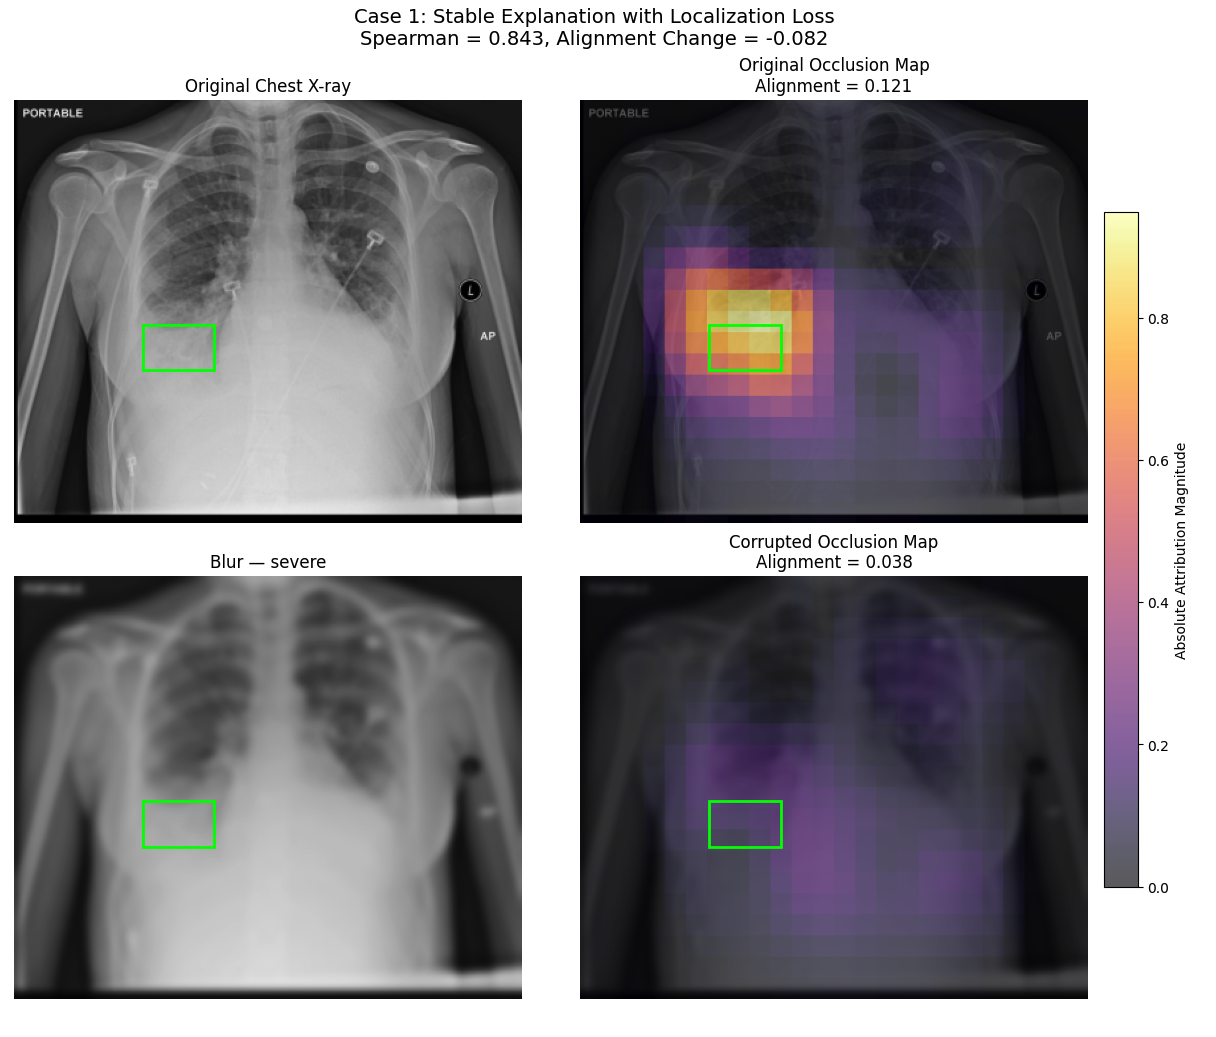


## Visual Evidence 2: Continuous Relationship Between Explanation Stability and Localization Change

To investigate whether explanation stability is associated with localization preservation beyond the predefined disagreement thresholds, we examined the continuous relationship between explanation similarity and localization alignment change across 2,700 evaluations.

The analysis considers three explanation methods: Integrated Gradients, Occlusion Sensitivity, and Score-CAM.

The following visualization illustrates how the relationship between explanation similarity and localization change varies across explanation methods, including cases where high similarity coexists with substantial localization deterioration.


###### Visualization of previously computed results.
###### No model inference or statistical tests are rerun here.

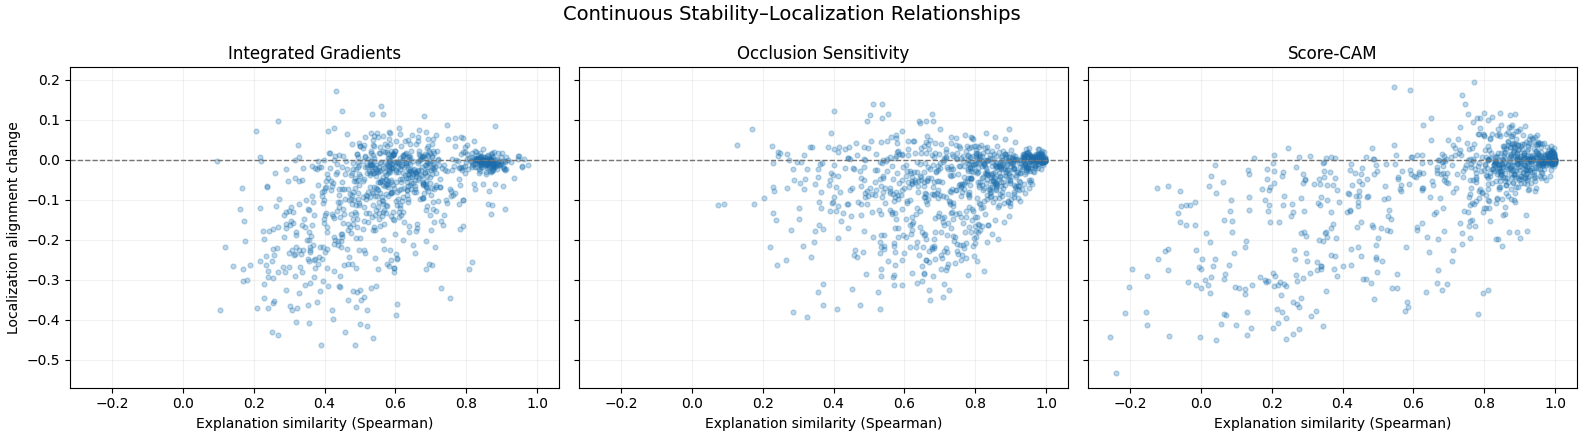


### Interpretation: Continuous Stability–Localization Relationships

Figure 2 illustrates the relationship between explanation similarity, measured using Spearman rank correlation, and changes in localization alignment across 2,700 evaluations involving Integrated Gradients, Occlusion Sensitivity, and Score-CAM.

Across all evaluations, explanation similarity was positively associated with localization alignment change (Spearman ρ = 0.508). This suggests that explanations exhibiting greater stability generally experienced smaller localization losses.

However, the relationship varied across explanation methods:

- **Integrated Gradients:** Spearman ρ = 0.504, indicating a moderate positive association.
- **Occlusion Sensitivity:** Spearman ρ = 0.336, indicating a weaker positive association.
- **Score-CAM:** Spearman ρ = 0.621, indicating the strongest positive association among the three methods.

Importantly, the scatterplots demonstrate that explanation similarity does not uniquely determine localization preservation. Observations with relatively high similarity can still exhibit negative localization alignment changes.

These results suggest that global explanation similarity provides useful information about localization preservation but is insufficient as a standalone measure of whether an explanation continues to emphasize the annotated opacity region.

The observed associations are descriptive and should not be interpreted as evidence that explanation stability causes localization preservation.



## Visual Evidence 3: Explanation Stability as a Localization-Loss Screening Signal

To evaluate the practical usefulness of explanation similarity, we examined whether lower similarity could identify evaluations experiencing an absolute localization alignment decrease of at least 0.05.

We assessed screening performance using ROC-AUC and image-cluster bootstrap confidence intervals, separately for Integrated Gradients, Occlusion Sensitivity, and Score-CAM.

The following figure compares the discrimination performance of explanation similarity across the three methods.


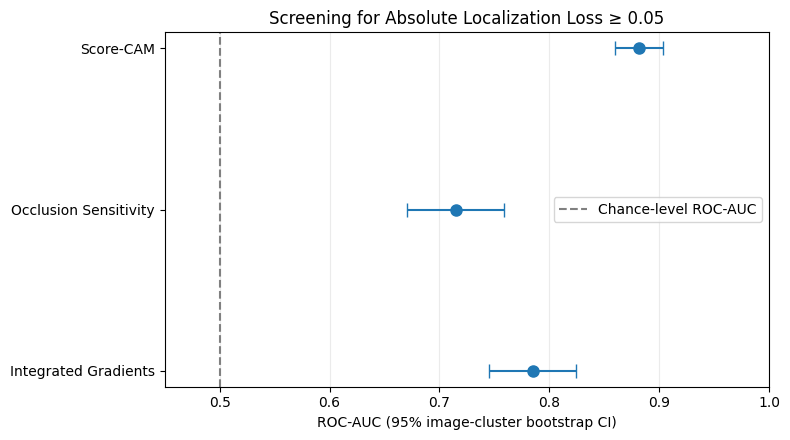

In [ ]:
# Visualization of previously computed results.
# No model inference or statistical tests are rerun here.
import matplotlib.pyplot as plt

methods = ["Integrated Gradients", "Occlusion Sensitivity", "Score-CAM"]

auc = [0.7850, 0.7150, 0.8821]
ci_lower = [0.7456, 0.6702, 0.8594]
ci_upper = [0.8240, 0.7586, 0.9037]

errors = [
    [a - lower for a, lower in zip(auc, ci_lower)],
    [upper - a for a, upper in zip(auc, ci_upper)],
]

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.errorbar(auc, methods, xerr=errors, fmt="o", capsize=5, markersize=8)

ax.axvline(0.5, color="gray", linestyle="--", label="Chance-level ROC-AUC")

ax.set_xlim(0.45, 1.0)
ax.set_xlabel("ROC-AUC (95% image-cluster bootstrap CI)")
ax.set_title("Screening for Absolute Localization Loss ≥ 0.05")
ax.grid(axis="x", alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()


### Interpretation: Screening Performance Across Explanation Methods

Figure 3 compares the ability of explanation similarity to discriminate between evaluations with and without substantial absolute localization loss, defined as an alignment decrease of at least 0.05.

Screening performance varied across the three explanation methods:

- **Score-CAM:** ROC-AUC = 0.8821 (95% CI: 0.8594–0.9037)
- **Integrated Gradients:** ROC-AUC = 0.7850 (95% CI: 0.7456–0.8240)
- **Occlusion Sensitivity:** ROC-AUC = 0.7150 (95% CI: 0.6702–0.7586)

The results indicate that explanation similarity contains useful information for identifying localization deterioration, although its discriminative performance differs by explanation method.

Across all 2,700 evaluations, the overall ROC-AUC was 0.7911. However, using a similarity threshold of 0.80 as a screening rule failed to identify 171 of the 1,145 evaluations experiencing substantial localization loss (14.93%).

These missed cases demonstrate that a relatively high explanation similarity does not guarantee preservation of localization alignment.

The findings support using explanation similarity as a complementary screening signal rather than treating it as a sufficient indicator of explanation reliability. ROC-AUC measures discrimination against the chosen localization-loss criterion; it does not establish explanation faithfulness or clinical validity.



## Visual Evidence 4: Image-Level Concentration of Stability–Localization Disagreements

To investigate whether stability–localization disagreements recur disproportionately in particular images, we examined the distribution of disagreement events across 150 annotated positive chest X-ray images.

We compared the observed proportion of disagreements occurring in the 20 most affected images with a condition-stratified permutation benchmark. The permutation procedure preserved disagreement totals within method, corruption type, and severity combinations while disrupting their association with individual images.

The following figure compares the observed concentration with the expected concentration under this permutation null model.


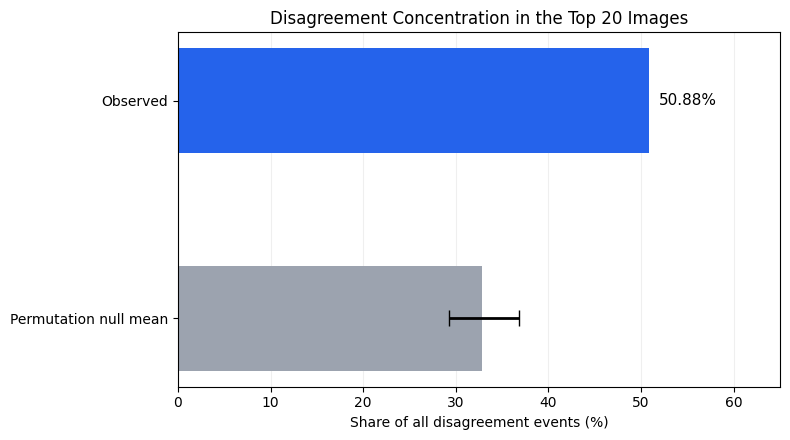

In [ ]:
# Visualization of previously computed results.
# No model inference or statistical tests are rerun here.
import matplotlib.pyplot as plt

observed = 50.88
null_mean = 32.84
null_lower = 29.24
null_upper = 36.84

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.barh(
    ["Permutation null mean", "Observed"],
    [null_mean, observed],
    color=["#9CA3AF", "#2563EB"],
    height=0.48,
)

ax.errorbar(
    null_mean,
    0,
    xerr=[[null_mean - null_lower], [null_upper - null_mean]],
    fmt="none",
    ecolor="black",
    capsize=6,
    linewidth=2,
)

for i, value in enumerate([null_mean, observed]):
    label_x = null_upper + 2 if i == 0 else value + 1

ax.text(label_x, i, f"{value:.2f}%", va="center", fontsize=11)

ax.set_xlim(0, 65)
ax.set_xlabel("Share of all disagreement events (%)")
ax.set_title("Disagreement Concentration in the Top 20 Images")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


### Interpretation: Image-Level Concentration of Disagreements

Figure 4 compares the observed concentration of stability–localization disagreements across chest X-ray images with a condition-stratified permutation benchmark.

Of the 150 annotated positive chest X-ray images, 70 (46.67%) exhibited at least one stability–localization disagreement. However, these events were not distributed evenly across images.

The 20 images with the highest disagreement counts accounted for 50.88% of all 171 disagreement events.

Under the condition-stratified permutation null model, the expected top-20 concentration was approximately 32.84%, with a 95% permutation interval of 29.24%–36.84%.

The observed concentration substantially exceeded this benchmark, suggesting that disagreements recur in particular images more frequently than expected under the specified null model.

This result highlights the importance of examining image-level recurrence rather than relying exclusively on aggregate disagreement rates.

However, the analysis does not establish why particular images experience repeated disagreements. Potential explanations involving image characteristics, annotation properties, or model behavior require further investigation.



## Final Synthesis

Taken together, the four visual analyses demonstrate that explanation stability and localization preservation are related but distinct properties.

The individual case study illustrates how a globally similar attribution map can lose alignment with an annotated opacity region. The continuous analysis shows that greater similarity is generally associated with better localization preservation, while the screening analysis demonstrates that similarity alone cannot identify every substantial localization loss. Finally, the image-level analysis indicates that stability–localization disagreements recur disproportionately within particular images relative to the specified permutation benchmark.

These findings support a multidimensional approach to explanation robustness assessment that considers global similarity, spatial localization, screening performance, and image-level recurrence.

The results should not be interpreted as establishing clinical validity or causal explanation faithfulness. Instead, they identify measurable limitations of relying on explanation similarity alone when evaluating attribution robustness under image corruption.
